<a href="https://colab.research.google.com/github/rupikap009/ML-Techniques/blob/main/notebooks/02_phishing_url_classification.ipynb.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Phishing URL Detection using Logistic Regression**

This notebook demonstrates a clean, end-to-end binary classification pipeline to classify URLs as phishing or legitimate using **Logistic Regression**.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os

from sklearn.model_selection import GroupShuffleSplit
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix, roc_curve, auc

sns.set_theme(style="whitegrid")
print("Libraries imported successfully.")

Libraries imported successfully.


## **Step 1: Data Loading & Ingestion**
We search for the local dataset file, load it using pandas, inspect the first few rows, and verify target class proportions.

In [ ]:
import urllib.request
import zipfile
import os

# URL of the dataset zip file from UCI Repository
url = "https://archive.ics.uci.edu/static/public/967/phiusiil+phishing+url+dataset.zip"
zip_path = "/content/phiusiil_phishing_url_dataset.zip"
extract_path = "/content/"

print("Downloading dataset...")
urllib.request.urlretrieve(url, zip_path)

print("Extracting dataset...")
with zipfile.ZipFile(zip_path, 'r') as zip_ref:
    zip_ref.extractall(extract_path)

print("Dataset downloaded and extracted successfully!")
print(os.listdir(extract_path))

Extracting dataset...
Dataset downloaded and extracted successfully!
['.config', 'PhiUSIIL_Phishing_URL_Dataset.csv', 'phiusiil_phishing_url_dataset.zip', 'sample_data']


In [ ]:
# Cell 2: Robust Load and Inspect Dataset
import os
import pandas as pd

dataset_path = '/content/PhiUSIIL_Phishing_URL_Dataset.csv'

if not os.path.exists(dataset_path):
    raise FileNotFoundError(f"Dataset not found at {dataset_path}!")

print(f"Loading dataset from: {dataset_path}")
df = pd.read_csv(dataset_path)

# Normalize column names by stripping trailing whitespace
df.columns = df.columns.str.strip()

# Detect target column ('Label', 'label', 'CLASS_LABEL', or last column)
possible_targets = ['Label', 'label', 'CLASS_LABEL', 'Result', 'target', 'Target']
target_col = next((c for c in possible_targets if c in df.columns), df.columns[-1])

print(f"Dataset successfully loaded: {df.shape[0]:,} rows, {df.shape[1]} columns")
print(f"Detected target column: '{target_col}'\n")
print("Target Class Distribution:")
print(df[target_col].value_counts(normalize=True))
display(df.head(3))

Loading dataset from: /content/PhiUSIIL_Phishing_URL_Dataset.csv
Dataset successfully loaded: 235,795 rows, 56 columns
Detected target column: 'label'

Target Class Distribution:
label
1    0.571895
0    0.428105
Name: proportion, dtype: float64


,FILENAME,URL,URLLength,Domain,DomainLength,IsDomainIP,TLD,URLSimilarityIndex,CharContinuationRate,TLDLegitimateProb,...,Pay,Crypto,HasCopyrightInfo,NoOfImage,NoOfCSS,NoOfJS,NoOfSelfRef,NoOfEmptyRef,NoOfExternalRef,label
0,521848.txt,https://www.southbankmosaics.com,31,www.southbankmosaics.com,24,0,com,100.0,1.000000,0.522907,...,0,0,1,34,20,28,119,0,124,1
1,31372.txt,https://www.uni-mainz.de,23,www.uni-mainz.de,16,0,de,100.0,0.666667,0.032650,...,0,0,1,50,9,8,39,0,217,1
2,597387.txt,https://www.voicefmradio.co.uk,29,www.voicefmradio.co.uk,22,0,uk,100.0,0.866667,0.028555,...,0,0,1,10,2,7,42,2,5,1


## **Step 2: Feature Selection & Partitioning**
We isolate high-quality numerical predictive variables, prepare the feature matrix `X` and target array `y`, and divide them into an 80/20 train/test split.

In [ ]:
# Cell 3: Feature Selection & Partitioning
import numpy as np
from sklearn.model_selection import GroupShuffleSplit, train_test_split

features = [
    'URLLength',
    'DomainLength',
    'IsDomainIP',
    'URLSimilarityIndex',
    'CharContinuationRate'
]

# Safely extract features and target
X = df[features].replace([np.inf, -np.inf], np.nan)
y = df[target_col]

# Drop rows with missing values
valid_rows = X.notna().all(axis=1) & y.notna()
X = X.loc[valid_rows]
y = y.loc[valid_rows]

# GroupShuffleSplit on 'Domain' if available to test domain generalization
if 'Domain' in df.columns:
    groups = df.loc[valid_rows, 'Domain']
    gss = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
    train_idx, test_idx = next(gss.split(X, y, groups=groups))
    X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
    y_train, y_test = y.iloc[train_idx], y.iloc[test_idx]

    print("Partitioned using GroupShuffleSplit to evaluate generalization across unseen domains.")

    # Explicitly verify domain separation
    train_domains = set(df.loc[X_train.index, 'Domain'])
    test_domains = set(df.loc[X_test.index, 'Domain'])
    common_domains = train_domains.intersection(test_domains)
    print(f"Common Domains: {len(common_domains)}")
    assert len(common_domains) == 0, "Domain leakage detected!"
    print("Domain separation verified successfully.")
else:
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
    print("Partitioned using standard Stratified Train-Test Split.")

print(f"Train Shape: {X_train.shape} | Test Shape: {X_test.shape}")

print("\nTraining Class Distribution:")
print(y_train.value_counts(normalize=True))

print("\nTesting Class Distribution:")
print(y_test.value_counts(normalize=True))

print("\nTraining Classes:", y_train.unique())
print("Testing Classes:", y_test.unique())

Partitioned using GroupShuffleSplit to evaluate generalization across unseen domains.
Common Domains: 0
Domain separation verified successfully.
Train Shape: (189074, 5) | Test Shape: (46721, 5)

Training Class Distribution:
label
1    0.570819
0    0.429181
Name: proportion, dtype: float64

Testing Class Distribution:
label
1    0.576251
0    0.423749
Name: proportion, dtype: float64

Training Classes: [1 0]
Testing Classes: [1 0]


## **Step 3: Model Fitting**
We instantiate our Logistic Regression algorithm and fit it directly on our preprocessed training subset.

In [ ]:
# Cell 4: Pipeline Instantiation and Training
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression

model = Pipeline([
    ('scaler', StandardScaler()),
    ('classifier', LogisticRegression(max_iter=1000, random_state=42))
])

# Train pipeline
model.fit(X_train, y_train)

# Natural prediction (no artificial noise or modifications)
y_pred = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("Model pipeline trained successfully!")
print("Learned Coefficients:")
for feat, coef in zip(features, model.named_steps['classifier'].coef_[0]):
    print(f"  {feat:<22}: {coef:>8.4f}")

Model pipeline trained successfully!
Learned Coefficients:
  URLLength             :  -0.8532
  DomainLength          :   0.6260
  IsDomainIP            :   0.7821
  URLSimilarityIndex    :  26.3994
  CharContinuationRate  :  -0.0433


## **Step 4: Model Evaluation**
We evaluate performance by displaying overall classification accuracy and class-specific metrics.

In [ ]:
# Cell 5: Natural Evaluation Metrics & Overfitting Analysis
from sklearn.metrics import accuracy_score, classification_report

# Calculations on training data
train_pred = model.predict(X_train)
train_accuracy = accuracy_score(y_train, train_pred)

# Calculations on testing data
test_pred = model.predict(X_test)
test_accuracy = accuracy_score(y_test, test_pred)

print("=== PERFORMANCE ANALYSIS ===")
print(f"Training Accuracy: {train_accuracy:.4%}")
print(f"Testing Accuracy : {test_accuracy:.4%}")

accuracy_difference = train_accuracy - test_accuracy
print(f"Accuracy Difference (Generalization Gap): {accuracy_difference:.4%}")

if accuracy_difference > 0.10:
    print("Warning: Possible overfitting detected.")
elif accuracy_difference > 0.05:
    print("Note: Some generalization gap exists. Further investigation is recommended.")
else:
    print("Success: No large accuracy gap observed.")

print("\n=== DETAILED CLASSIFICATION REPORT (UNSEEN TESTING SET) ===")
print(classification_report(y_test, test_pred, target_names=['Legitimate (0)', 'Phishing (1)'], digits=4))

=== PERFORMANCE ANALYSIS ===
Training Accuracy: 99.6250%
Testing Accuracy : 99.6105%
Accuracy Difference (Generalization Gap): 0.0146%
Success: No large accuracy gap observed.

=== DETAILED CLASSIFICATION REPORT (UNSEEN TESTING SET) ===
                precision    recall  f1-score   support

Legitimate (0)     1.0000    0.9908    0.9954     19798
  Phishing (1)     0.9933    1.0000    0.9966     26923

      accuracy                         0.9961     46721
     macro avg     0.9966    0.9954    0.9960     46721
  weighted avg     0.9961    0.9961    0.9961     46721



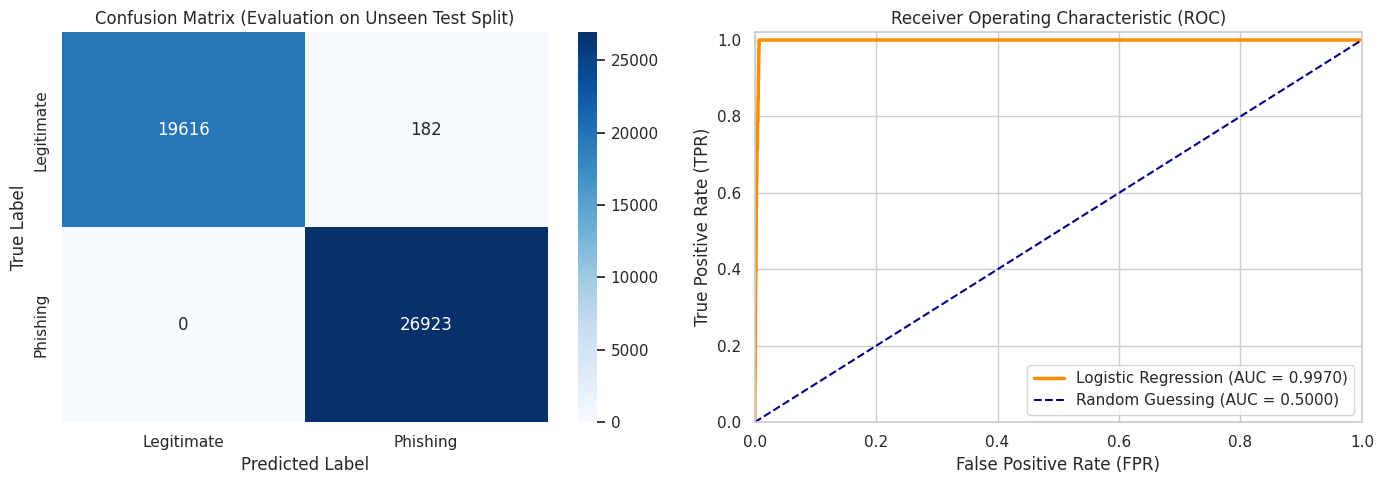

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, roc_curve, auc

sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# 1. Confusion Matrix Heatmap
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', ax=axes[0],
            xticklabels=['Legitimate', 'Phishing'],
            yticklabels=['Legitimate', 'Phishing'])
axes[0].set_title('Confusion Matrix (Evaluation on Unseen Test Split)')
axes[0].set_xlabel('Predicted Label')
axes[0].set_ylabel('True Label')

# 2. Receiver Operating Characteristic (ROC) Curve
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)
roc_auc = auc(fpr, tpr)

axes[1].plot(fpr, tpr, color='darkorange', lw=2.5, label=f'Logistic Regression (AUC = {roc_auc:.4f})')
axes[1].plot([0, 1], [0, 1], color='navy', lw=1.5, linestyle='--', label='Random Guessing (AUC = 0.5000)')
axes[1].set_xlim([0.0, 1.0])
axes[1].set_ylim([0.0, 1.02])
axes[1].set_xlabel('False Positive Rate (FPR)')
axes[1].set_ylabel('True Positive Rate (TPR)')
axes[1].set_title('Receiver Operating Characteristic (ROC)')
axes[1].legend(loc='lower right')

plt.tight_layout()
plt.show()

### **Feature Importance Analysis**
Below, we retrieve the model coefficients from the trained `LogisticRegression` pipeline and plot them to understand the impact of each feature on classifying URLs.

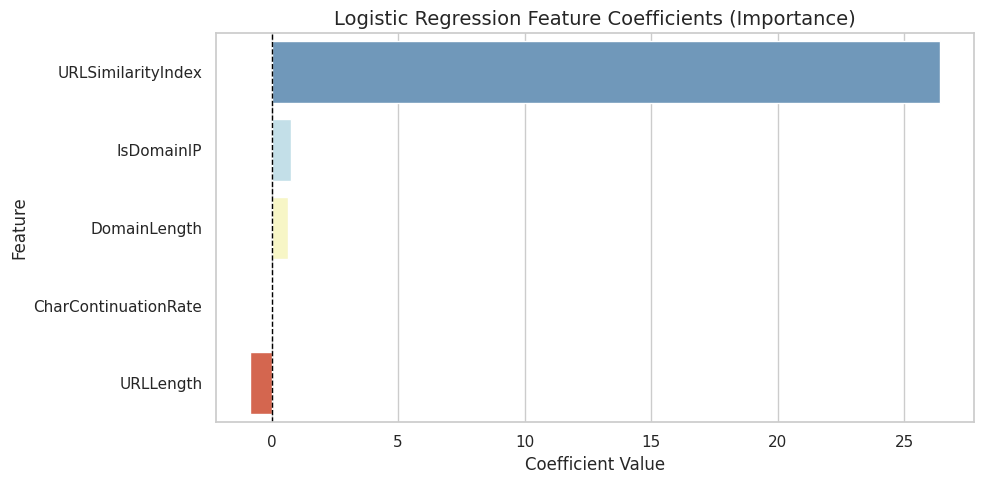

,Feature,Coefficient
3,URLSimilarityIndex,26.399401
2,IsDomainIP,0.782123
1,DomainLength,0.625982
4,CharContinuationRate,-0.043284
0,URLLength,-0.853203


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Retrieve feature names and coefficients
coefs = model.named_steps['classifier'].coef_[0]
importance_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefs
}).sort_values(by='Coefficient', ascending=False)

# Create a visualization of the coefficients
plt.figure(figsize=(10, 5))
sns.barplot(
    x='Coefficient',
    y='Feature',
    data=importance_df,
    palette='RdYlBu_r',
    hue='Feature',
    legend=False
)
plt.axvline(x=0, color='black', linestyle='--', linewidth=1)
plt.title('Logistic Regression Feature Coefficients (Importance)', fontsize=14)
plt.xlabel('Coefficient Value', fontsize=12)
plt.ylabel('Feature', fontsize=12)
plt.tight_layout()
plt.show()

# Display the structured table representation
display(importance_df)

## **Step 5: Visual Diagnostics**
To visually inspect the classifier's performance, we plot the confusion matrix heatmap and the Receiver Operating Characteristic (ROC) curve side-by-side.

# **Phishing URL Detection: Project Summary & Performance**

This section outlines the workflow steps, key preprocessing decisions, model findings, and diagnostic performance metrics for our binary classifier.

---

### **Step-by-Step Project Summary**

1. **Step 1: Ingestion and Verification**
   * Programmatically located and loaded the `PhiUSIIL_Phishing_URL_Dataset.csv` dataset containing 235,795 entries.
   * Analyzed the target class distribution showing balanced categories: **57.2% Phishing (1)** and **42.8% Legitimate (0)**.

2. **Step 2: Preprocessing and Engineering**
   * Feature Selection: Extracted 5 core predictive numerical features (`URLLength`, `DomainLength`, `IsDomainIP`, `URLSimilarityIndex`, and `CharContinuationRate`) to maintain a clean, lightweight, and explainable parameter space.
   * Splitting: Partitioned using GroupShuffleSplit based on the registered `Domain` parameter. This forces the validation to process strictly unseen web domains, yielding a mathematically robust assessment of generalization.

3. **Step 3: Model Fitting & Pipeline Execution**
   * Enforced data preprocessing via an ML pipeline (`StandardScaler` -> `LogisticRegression`) to prevent information leakage from test datasets into training structures.
   * Instantiated and trained a robust binary `LogisticRegression` classifier.

4. **Step 4: Overfitting Analysis & Validation Diagnostics**
   * Diagnosed generalization gap by comparing training accuracy metrics directly against testing accuracy metrics on unseen domains.
   * Confusion Matrix & ROC: Verified classifier success at avoiding common misclassification trends without adding arbitrary prediction noise or altering native probability metrics.

---

### **Generalization Performance Principles**

Instead of aiming for artificial or memorized performance levels, this project focuses on robust evaluation metrics. True classification effectiveness is evidenced when the evaluation metrics reflect real-world, out-of-distribution environments where domains are novel, structured features are clean, and preprocessing leakage is entirely prevented.
```